# Normalising Flow

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


The normalising flow model is a stochastic surrogate with efficiently computable exact density.

## When this might be a good fit


The normalising flow surrogate is a good option when stochasticity and/or evaluating the exact density of the surrogate is needed. Access to this density enables the surrogate to be used in parameter inference pipelines like MCMC, Variational Inference or Simulation-Based Inference (SBI).

Architecturally it is implemented as a Transformer Autoregressive Flow (TARFlow), which is a modern normalising flow design that composes transformer blocks into an end-to-end invertible architecture. Currently it only supports static inputs. Its density is that of the fitted continuous surrogate, not the exact likelihood of the simulator.

## How Normalising Flows work

### Maximum likelihood via change of variables
A Normalising Flow parametrises an invertible transformation $f_{\theta}$ from the data distribution $p_{\mathrm{data}}$ to a noise distribution $p_0$ (usually Gaussian). Once trained the network can be inverted to transform noise samples into data. This transformation also has an associated density $p_{\mathrm{model}}$ which is accessible via the change of variable formula

$$
\log p_{\mathrm{model}}(x)=\log p_0(f_{\theta}(x))+\log\vert\mathrm{det}(\frac{df_{\theta}(x)}{dx})\vert
$$

Architecturally Normalising Flows are designed to be exactly invertible with log-determinants that can be efficiently computed. This allows a maximum likelihood estimation objective to be implemented as

$$
\min_{\theta}\; -\log p_0(f_{\theta}(x))-\log\vert\mathrm{det}(\frac{df_{\theta}(x)}{dx})\vert
$$


### Architecture

Normalising Flows have a rich literature with architectures that make different tradeoffs and until recently they were not regarded as scalable as generative models. Recently, the Transformer Autoregressive Flow (TARFlow) [@tarflow] has emerged as a scalable approach to Normalising Flows. Like many Normalising Flows the overall network $f_{\theta}$ is a composition of several invertible *blocks* $f_{M}\circ f_{M-1}\cdots\circ f_{1}$. Each of these blocks flips the order of the sequence with $\pi(x)$, and predicts scale $\alpha$ and shift $\mu$ parameters for each of the elements in the sequence with an autoregressive transformer $T(x)$:
$$
\begin{align}
&x^{\mathrm{output}}_{i}=(x^{\mathrm{input}}_{i}-\mu_{i})\odot \exp (-\alpha_i)\\
&\text{where } \mu_i \text{ and } \alpha_i \text{ are predicted by } T(x_{<i})\\
\end{align}
$$

![An invertible transformer autoregressive flow block predicts scale and shift.](https://ojwatson.github.io/metis/models/images/transformer-ar-flow-block.svg)

Transformer Autoregressive Flow Block. Adapted from @tarflow.

Crucially, since the transformer is causal, $\alpha_i$ and $\mu_i$ only depend on the elements strictly preceding $i$. Hence, the block can be exactly inverted by autoregressively rolling out

$$
x^{\mathrm{input}}_{i}=(x^{\mathrm{output}}_{i}\odot\exp(\alpha_i))+\mu_i
$$


Normalising flows can have numerical difficulties on high-dimensional data.
METIS does not apply the noise augmentation and Tweedie denoising used in the
image experiments of @tarflow. Inspect both samples and held-out densities.



## Configuring an iTARFlow model

Pass architecture options to `Surrogate("itarflow", model_options={...})`:

| Option | Meaning | Default |
|---|---|---:|
| `channels` | Hidden dimension (width) | 64 |
| `num_blocks` | Number of invertible flow blocks | 2 |
| `num_layers` | Transformer layers per flow block | 2 |
| `num_heads` | Number of attention heads | 4 |
| `num_static_tokens` | Tokens encoding the static inputs | 4 |
| `patch_size` | Time points grouped into one token | 1 |

A larger `patch_size` shortens the sequence processed by the model and must
divide the number of time points. Input and output dimensions are inferred
from the bank. Through [Hydra](https://ojwatson.github.io/metis/basics/hydra.html):

```bash
uv run metis train model=itarflow model.model_options.channels=128
```

## Training on SIRDS

We use the full [SIRDS bank](https://ojwatson.github.io/metis/basics/sirds-example.html): 1,000 parameter
settings, five realisations per setting and all 200 daily outputs. The grouped
split matches the [training tutorial](https://ojwatson.github.io/metis/basics/training.html): 600 settings for
training, 200 for validation and 200 for testing. This CPU fit uses 1,000
optimizer steps.

For this 200-day example we set `patch_size=5`, grouping five daily time points
into each transformer token. The model still generates all 200 daily outputs;
the shorter token sequence makes training and sampling faster.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "itarflow",
    model_options={"channels": 32, "num_blocks": 2, "num_layers": 1, "num_heads": 2,
                   "patch_size": 5},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)

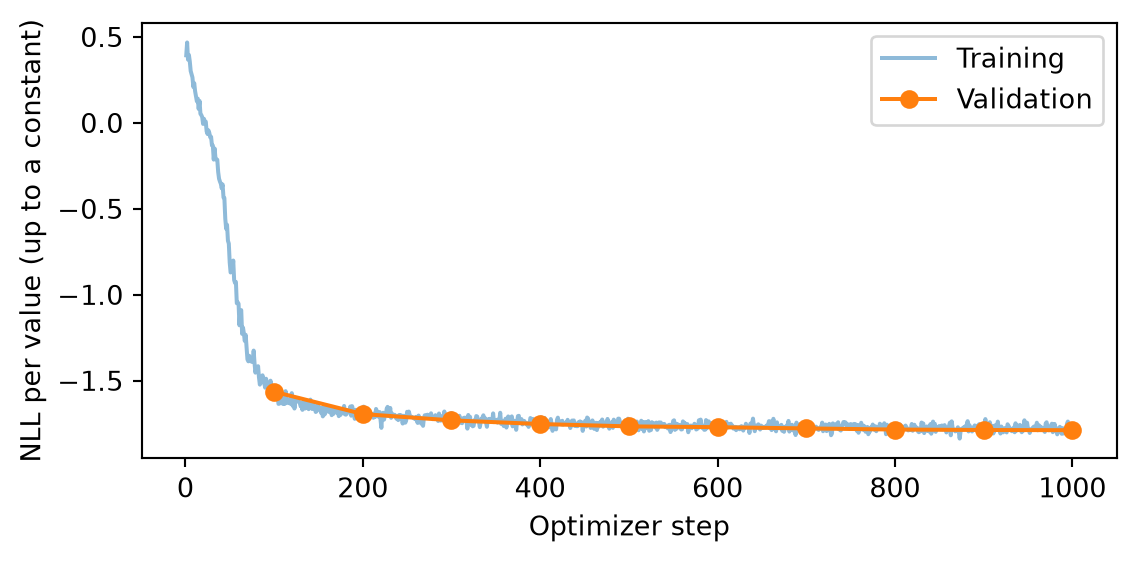

In [3]:
#| code-fold: true
#| code-summary: "Plot training and validation loss"
#| fig-cap: "iTARFlow: loss on the full SIRDS bank: 600 training settings and 200 validation settings."
validation = [row for row in model.history if "validation_loss" in row]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([row["step"] for row in model.history],
        [row["train_loss"] for row in model.history], alpha=0.5, label="Training")
ax.plot([row["step"] for row in validation],
        [row["validation_loss"] for row in validation], "o-", label="Validation")
ax.set(xlabel="Optimizer step", ylabel="NLL per value (up to a constant)")
ax.legend()
fig.tight_layout()
plt.show()

*iTARFlow: loss on the full SIRDS bank: 600 training settings and 200 validation settings.*

Generate several trajectories for the same held-out inputs by changing the
initial noise. The band below describes variation in surrogate samples, not
uncertainty in fitted model weights.

In [4]:
inputs = split.test.inputs[:1]
draws = model.sample(inputs, n_samples=100, seed=13)[0]
print("Samples × times × outputs:", draws.shape)
print(f"Smallest generated compartment count: {draws.min():.1f}")

Samples × times × outputs: (100, 200, 4)
Smallest generated compartment count: -412.9


/home/runner/work/metis/metis/src/metis/surrogate.py:737: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


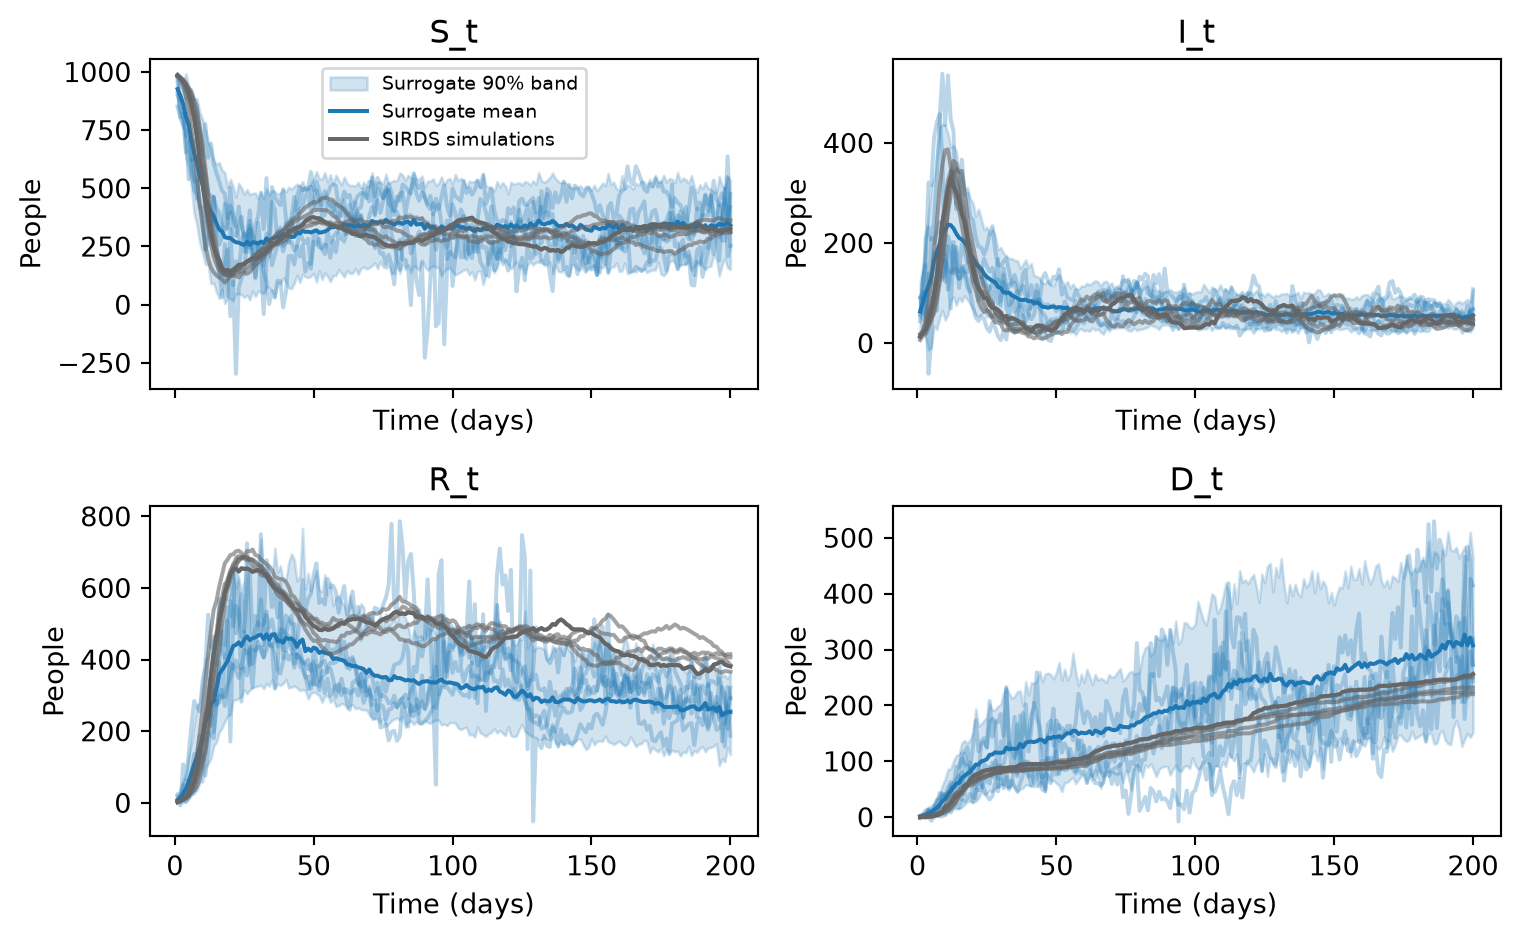

In [5]:
#| code-fold: true
#| code-summary: "Compare surrogate samples with SIRDS simulations"
#| fig-cap: "iTARFlow: generated trajectories and five SIRDS simulations at the first held-out parameter setting. Shading spans the pointwise 5th–95th percentiles of 100 surrogate draws, after fitting 600 settings from the full 200-day SIRDS bank."
same_inputs = np.all(split.test.inputs == inputs[0], axis=1)
replicates = split.test.outputs[same_inputs]
low, high = np.quantile(draws, [0.05, 0.95], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    ax.fill_between(bank.times, low[:, channel], high[:, channel],
                    color="C0", alpha=0.2, label="Surrogate 90% band")
    ax.plot(bank.times, draws[:5, :, channel].T, color="C0", alpha=0.3)
    ax.plot(bank.times, draws.mean(axis=0)[:, channel], color="C0", label="Surrogate mean")
    ax.plot(bank.times, replicates[:, :, channel].T, color="0.4", alpha=0.6)
    ax.plot(bank.times, replicates[0, :, channel], color="0.4", label="SIRDS simulations")
    ax.set(title=bank.output_names[channel], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

*iTARFlow: generated trajectories and five SIRDS simulations at the first held-out parameter setting. Shading spans the pointwise 5th–95th percentiles of 100 surrogate draws, after fitting 600 settings from the full 200-day SIRDS bank.*

Here the generated recovered and dead compartments drift from the simulator
paths, and some draws are negative. This short fit needs improvement before use
as a SIRDS surrogate. Check performance across the whole held-out bank, as in
the [training tutorial](https://ojwatson.github.io/metis/basics/training.html); a density value alone does not
establish that the model reproduces the SIRDS dynamics or its nonnegative counts.

The flow can also evaluate the log density of a held-out trajectory, in the
original output units:

In [6]:
log_density = model.log_prob(inputs, split.test.outputs[:1])
print("Held-out log density:", log_density[0])

Held-out log density: -3141.158725860899


/home/runner/work/metis/metis/src/metis/surrogate.py:849: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  self.log_prob_tensor(


SIRDS outputs are integer counts with a fixed population total. A continuous
flow approximates these outputs; its density is not the probability of an
integer trajectory. See [surrogate likelihoods](https://ojwatson.github.io/metis/sbi/vi-mcmc.html) before
using this quantity for inference.